# Biology Analysis Lab

Three controlled synthetic cases. These are teaching data, not patient data or evidence of clinical efficacy.

## Setup

Run from the repository root after installing `requirements.lock`. The validation runner executes this notebook and retains a separate executed copy. All code blocks below run against the same versioned implementation.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import inference_pitfalls
OUT = Path("artifacts/run/inference_pitfalls")

## 1. Frequencies and absolute counts

A parent population shrinks from 1,000,000 to 400,000 viable cells. The target rises from 20% to 35% of parent events. Compute both target counts before making a biological claim. Independent arithmetic: 1,000,000 × 0.20 = 200,000; 400,000 × 0.35 = 140,000. Frequency increases while absolute count decreases 30%. This assumes representative flow sampling and a valid independent total viable-cell estimate.

## 2. Biological replication

Eight donors each contribute twelve technical measurement pairs. First average technical replicates within donor and condition, then calculate donor-level differences. Compare a paired t interval with a deliberately wrong analysis pretending 96 technical pairs are independent. The exact sign-flip calculation requires exchangeable/symmetric signs under the null; a small t p-value is not a guarantee that its assumptions hold.

## 3. A negative control for leakage

Generate random donor labels independently of measured donor fingerprints. Repeat each donor eight times. Compare a random-row split with a donor-group split using the same StandardScaler/KNN pipeline. A random-row score can reward donor identification rather than biology. The fixed null simulation illustrates this mechanism; it does not prove every biological dataset will show the same gap.

## Execute the complete analysis

Inspect the returned results and tables. No outcome is hand-written into the code or edited to create a better story.

In [2]:
summary = inference_pitfalls.run(OUT)
print(json.dumps(summary, indent=2))

{
  "source": "Entirely synthetic, seeded teaching examples. No actual patient or product data.",
  "cell_count_case": [
    {
      "condition": "Before",
      "total_viable_cells": 1000000,
      "target_events": 20000,
      "parent_events": 100000,
      "target_fraction": 0.2,
      "absolute_target_cells": 200000.0
    },
    {
      "condition": "After",
      "total_viable_cells": 400000,
      "target_events": 35000,
      "parent_events": 100000,
      "target_fraction": 0.35,
      "absolute_target_cells": 140000.0
    }
  ],
  "correct_donor_analysis": {
    "n_donors": 8,
    "mean_difference": 0.9969167018392264,
    "t": 0.9195026269912787,
    "df": 7,
    "p_t": 0.3884197494400864,
    "ci95": [
      -1.5667882194837297,
      3.5606216231621826
    ],
    "exact_sign_flip_p": 0.5234375
  },
  "deliberately_wrong_technical_pair_analysis": {
    "n_pretended_independent_pairs": 96,
    "p": 0.0010367743567186198,
    "ci95": [
      0.41220465671857276,
      1.581628

,condition,total_viable_cells,target_events,parent_events,target_fraction,absolute_target_cells
0,Before,1000000,20000,100000,0.20,200000.0
1,After,400000,35000,100000,0.35,140000.0


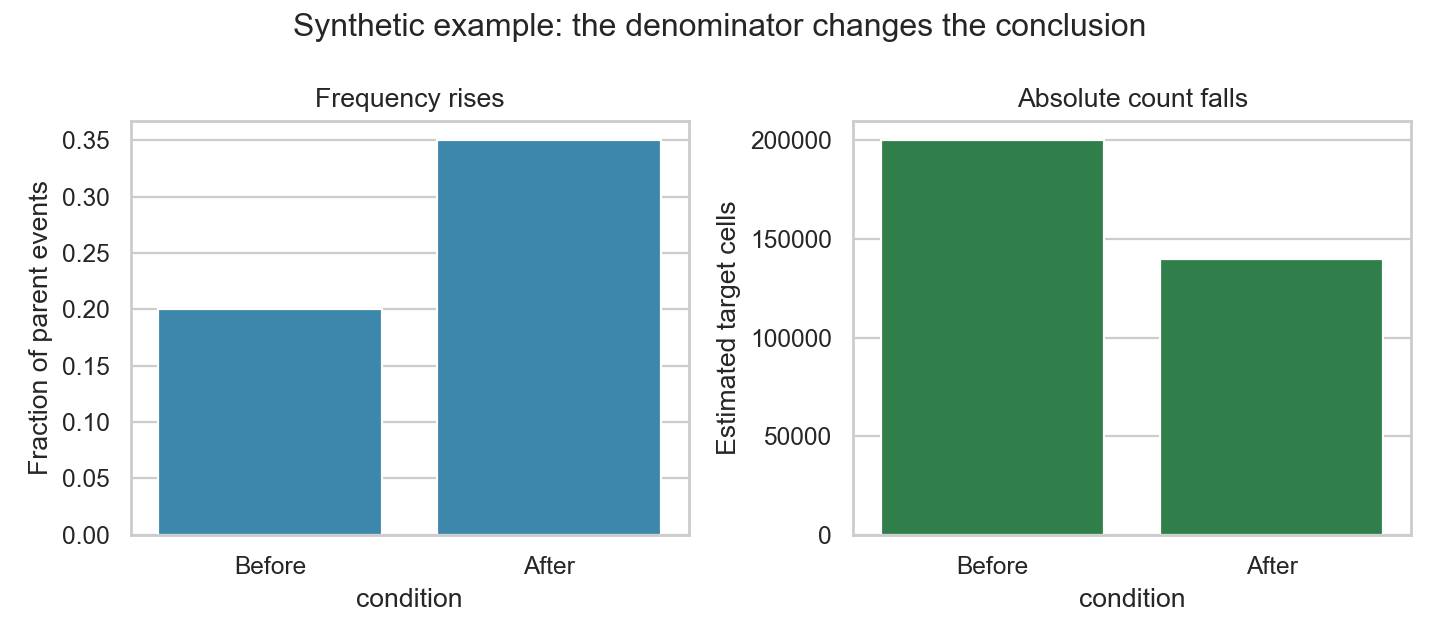

In [3]:
display(pd.read_csv(OUT / "cell_counts.csv"))
display(Image(filename=str(OUT / "counts_vs_percentages.png")))

,donor,control,treated
0,D01,49.132883,47.121520
1,D02,46.156066,45.182332
2,D03,47.364466,47.312474
3,D04,40.565892,40.577958
4,D05,47.298450,47.319155
5,D06,45.474618,46.486190
6,D07,49.557302,51.535056
7,D08,45.589173,53.579498


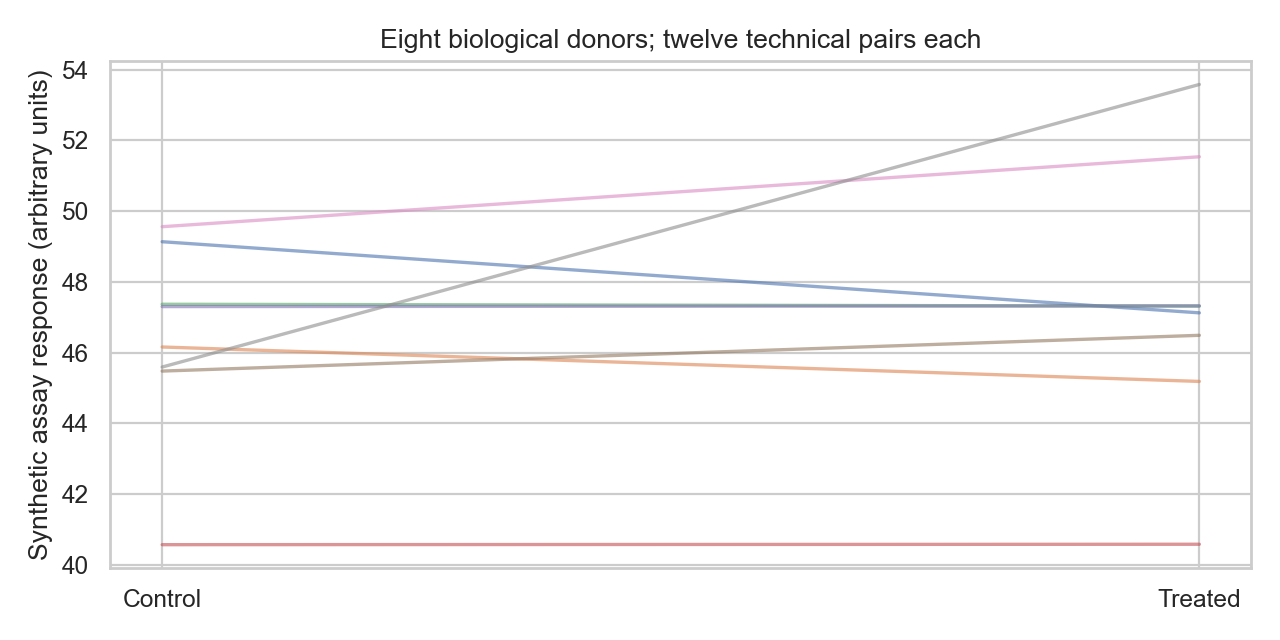

In [4]:
display(pd.read_csv(OUT / "donor_means.csv"))
display(Image(filename=str(OUT / "donor_pairs.png")))

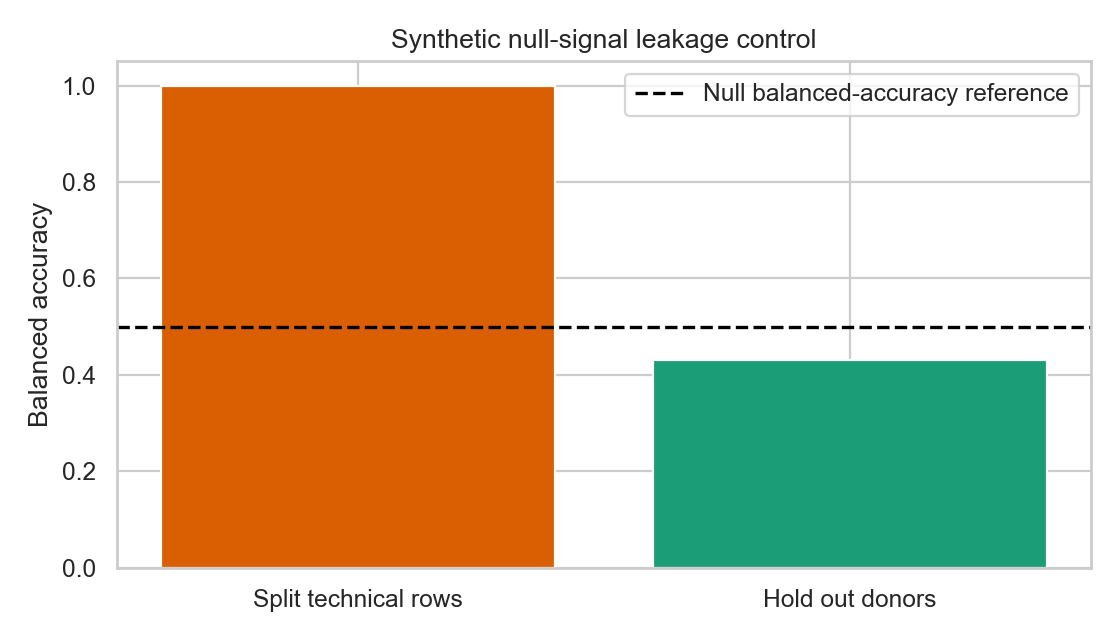

In [5]:
display(Image(filename=str(OUT / "leakage.png")))

## What was validated

`tests/` checks hand-calculated examples, independent formulations, malformed inputs and relevant invariants. `python scripts/validate.py` runs pytest, the full pipeline and this notebook. Passing these checks is bounded computational evidence, not clinical validation. See `reports/reference/inference_pitfalls/FINDINGS.md` for actual results and limitations.